# 03 · Previsão do 2º turno (B4)

Previsão, por município, da fatia de Lula entre os dois finalistas no 2º turno de 25/10.
Ela é **congelada** antes da eleição (commit + tag `previsao-2t-2026-<versão>`) e avaliada
depois pelos critérios registrados em `docs/hipoteses.md` (seção B4).

A previsão tem duas partes, que são avaliadas separadamente:

1. **Nível nacional:** quanto Lula terá no país. Os dados do 1º turno não decidem isso,
   então ele vem das pesquisas de 2º turno, corrigidas pelo erro que cada instituto teve no
   1º turno.
2. **Geografia:** como esse total se distribui entre os municípios. Aqui os dados mandam:
   em 2022, o 1º turno previa o 2º com correlação de 0,9985 entre municípios.

Este notebook lê a versão congelada; ele não gera previsões (isso é `just previsao`).

In [1]:
import json

import altair as alt
import numpy as np
import polars as pl

from kingsrace import paths, resultados
from kingsrace.models.previsao_2t import (
    aplica_transferencias,
    calibra_logits,
    calibra_nivel,
    estima_compressao,
)
from kingsrace.viz import tema  # noqa: F401  (registra e ativa o tema do projeto)
from kingsrace.viz.tema import SERIES, TINTA

resultados.configura_altair()
live = resultados.abre("03_previsao_2t")  # métricas e gráficos em resultados/03_previsao_2t/

VERSAO = resultados.params("previsao_2t")["versao"]
P, REF = paths.PROCESSED, paths.REFERENCE
previsao = pl.read_csv(REF / "previsoes" / f"previsao_2t_2026_{VERSAO}.csv")
meta = json.loads((REF / "previsoes" / f"previsao_2t_2026_{VERSAO}.json").read_text("utf8"))
print(f"Versão {meta['versao']} · corte das pesquisas {meta['corte_pesquisas']}")
print(f"Gerada em {meta['gerada_em']} · commit {meta['commit'][:7]}")

Versão v1 · corte das pesquisas 2026-10-08

Gerada em 2026-10-08T22:56:00-03:00 · commit 8bf1f17

## 1. A geografia: o que o 2022 ensina

**Backtest:** aplicamos cada variante ao 1º turno de 2022, calibramos no resultado real do
2º turno (para isolar a geografia do nível) e medimos o erro por município.

- **G0 · deslocamento uniforme:** todos os municípios se movem igual, em logit.
- **G1 · transferências por perfil:** os votos de cada candidato eliminado vão para Lula ou
  para o adversário segundo taxas por perfil (`data/reference/transferencias_2t.csv`).
- **G2 · uniforme + compressão:** como G0, mas os redutos de cada lado andam um pouco para
  o centro. A inclinação é estimada no próprio 2022, então aqui o G2 joga em casa: o erro
  dele no backtest é otimista.

In [2]:
painel22 = pl.read_parquet(P / "painel_municipio.parquet").filter(pl.col("ano") == 2022)
votos22 = pl.read_parquet(P / "votos_municipio.parquet").filter(
    (pl.col("ano") == 2022) & (pl.col("turno") == 1) & pl.col("cd_ibge").is_not_null()
)
taxas22 = pl.read_csv(REF / "transferencias_2t.csv").filter(pl.col("ano") == 2022)

bt = (
    painel22.filter(pl.col("turno") == 1)
    .select("cd_ibge", "uf", pt1="votos_pt", adv1="votos_adv", lg1="pt_2p_logit")
    .join(
        painel22.filter(pl.col("turno") == 2).select(
            "cd_ibge", real="pt_2p", lg2="pt_2p_logit", v2=pl.col("votos_pt") + pl.col("votos_adv")
        ),
        on="cd_ibge",
    )
    .join(aplica_transferencias(votos22, taxas22), on="cd_ibge")
    .sort("cd_ibge")
)
alvo22 = float((bt["real"] * bt["v2"]).sum() / bt["v2"].sum())
pt1, adv1 = bt["pt1"].to_numpy().astype(float), bt["adv1"].to_numpy().astype(float)
lg1 = bt["lg1"].to_numpy()
b22 = estima_compressao(lg1, bt["lg2"].to_numpy())
prev22 = {
    "G0 · uniforme": calibra_nivel(pt1, adv1, alvo22)[1],
    "G1 · transferências": calibra_nivel(bt["pt_est"].to_numpy(), bt["adv_est"].to_numpy(), alvo22)[
        1
    ],
    "G2 · compressão (na amostra)": calibra_logits(
        lg1 + b22 * (lg1 - lg1.mean()), pt1 + adv1, alvo22
    )[1],
    "Ingênua · repetir o 1º turno": pt1 / (pt1 + adv1),
}
real22 = bt["real"].to_numpy()
backtest = pl.DataFrame(
    [
        {
            "variante": nome,
            "rmse_pp": float(np.sqrt(np.mean((100 * (s - real22)) ** 2))),
            "p90_pp": float(np.quantile(np.abs(100 * (s - real22)), 0.9)),
        }
        for nome, s in prev22.items()
    ]
)
for linha in backtest.iter_rows(named=True):
    chave = resultados.chave(linha["variante"].split()[0])  # G0, G1, G2, Ingenua
    resultados.metricas(
        live, f"B4/backtest_2022/{chave}", {k: linha[k] for k in ("rmse_pp", "p90_pp")}
    )
resultados.metrica(live, "B4/backtest_2022/compressao_b", b22)
print(f"Compressão estimada em 2022: b = {b22:+.4f}")
backtest

Compressão estimada em 2022: b = -0.0139

variante,rmse_pp,p90_pp
str,f64,f64
"""G0 · uniforme""",0.951648,1.499225
"""G1 · transferências""",1.16076,1.818302
"""G2 · compressão (na amostra)""",0.925562,1.439032
"""Ingênua · repetir o 1º turno""",2.109058,3.159325


**Como ler:** erro típico por município, em pp, prevendo o 2º turno de 2022 a partir do 1º.
A referência ingênua (repetir o 1º turno) erra mais porque ignora o deslocamento nacional;
as demais já recebem o nível certo, então o que se compara entre elas é só a geografia.

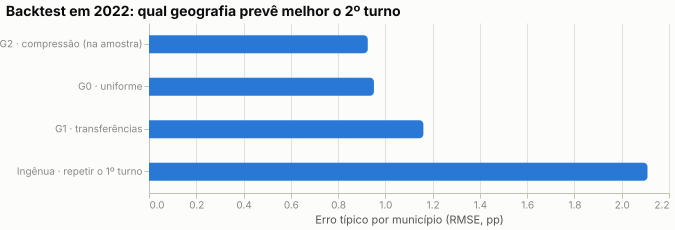

In [3]:
resultados.grafico(
    live,
    "B4_backtest_2022",
    alt.Chart(backtest)
    .mark_bar(cornerRadiusEnd=4, height=18, color=SERIES[0])
    .encode(
        x=alt.X("rmse_pp:Q", title="Erro típico por município (RMSE, pp)"),
        y=alt.Y("variante:N", sort="x", title=None),
        tooltip=[
            alt.Tooltip("variante:N", title="Variante"),
            alt.Tooltip("rmse_pp:Q", title="RMSE (pp)", format=".2f"),
            alt.Tooltip("p90_pp:Q", title="90% dos municípios erram menos de (pp)", format=".2f"),
        ],
    )
    .properties(
        width=520, height=170, title="Backtest em 2022: qual geografia prevê melhor o 2º turno"
    ),
)

**O que observar:** as transferências por perfil (G1) **erram mais** que o deslocamento
uniforme. Em 2022, o que moveu os municípios entre os turnos não foi onde Tebet e Ciro eram
fortes (a correlação do desvio com a fatia dos outros candidatos é ≈ 0). O padrão que
aparece é de **compressão**: onde o PT era mais forte no 1º turno, ele avançou menos que o
uniforme no 2º. Por isso o central é o G0, e G1 e G2 vão junto como apostas alternativas.

## 2. O nível nacional: pesquisas corrigidas

Para cada instituto, a fatia de Lula entre os dois finalistas na última pesquisa de 2º turno,
menos λ vezes o viés do instituto no 1º turno. **Por que só uma fração?** Em 2022, o Datafolha
superestimou Lula em ~5 pp no 1º turno e em ~1 pp no 2º: os institutos ajustam entre os turnos,
e o erro não se repete inteiro. O central usa λ = 0,5, com faixa de λ = 0 a λ = 1.

In [4]:
niveis = meta["niveis"]
pl.DataFrame(niveis["central"]["detalhe"]).with_columns(
    (100 * pl.col("s")).round(2).alias("Lula na pesquisa (%)"),
    (100 * pl.col("vies")).round(2).alias("viés no 1º turno (pp)"),
    (100 * pl.col("corrigido")).round(2).alias("corrigido, λ = 0,5 (%)"),
).drop("s", "vies", "corrigido")

instituto,campo_fim,Lula na pesquisa (%),viés no 1º turno (pp),"corrigido, λ = 0,5 (%)"
str,str,f64,f64,f64
"""Datafolha""","""2026-10-08""",48.0,2.24,46.88


In [5]:
cenarios = pl.DataFrame(
    [
        {"cenario": "1º turno (real)", "lula": 100 * meta["pt_2p_1t_real"]},
        {
            "cenario": "Pesquisa sem correção (λ = 0)",
            "lula": 100 * niveis["sem_correcao"]["alvo_nacional"],
        },
        {"cenario": "Central (λ = 0,5)", "lula": 100 * niveis["central"]["alvo_nacional"]},
        {
            "cenario": "Viés repetido inteiro (λ = 1)",
            "lula": 100 * niveis["correcao_total"]["alvo_nacional"],
        },
    ]
)
resultados.metricas(
    live,
    "B4/previsao",
    {
        "primeiro_turno_pct": 100 * meta["pt_2p_1t_real"],
        **{f"{n}_pct": 100 * niveis[n]["alvo_nacional"] for n in niveis},
    },
)
cenarios

cenario,lula
str,f64
"""1º turno (real)""",48.979579
"""Pesquisa sem correção (λ = 0)""",48.0
"""Central (λ = 0,5)""",46.880033
"""Viés repetido inteiro (λ = 1)""",45.760067


## 3. A previsão por UF

**Como ler:** para cada UF, o ponto é a previsão central de Lula (geografia G0, λ = 0,5); a
barra vai do cenário λ = 1 ao λ = 0; o tracinho cinza é a fatia de Lula entre os dois no
1º turno. A linha tracejada marca 50%.

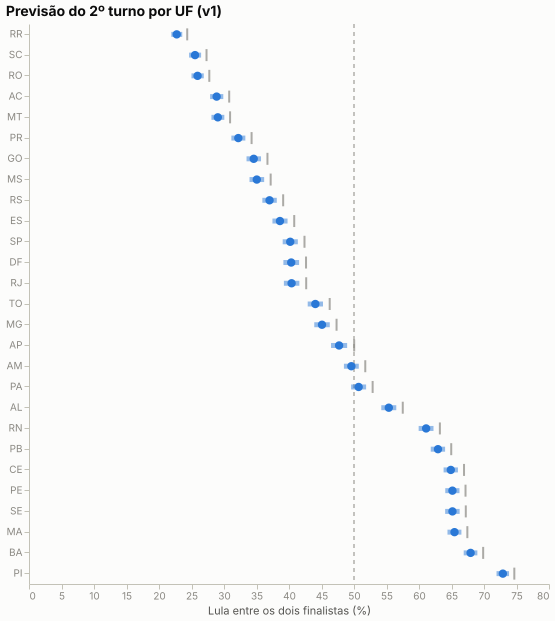

In [6]:
def por_uf(colunas):
    return previsao.group_by("uf").agg(
        *[
            (
                (pl.col(c) * pl.col("votos_validos_est")).sum()
                / pl.col("votos_validos_est").sum()
                * 100
            ).alias(c)
            for c in colunas
        ]
    )


colunas = [
    "pt_2p_1t",
    "pt_2p",
    "pt_2p_sem_correcao",
    "pt_2p_correcao_total",
    "pt_2p_g1_transferencias",
    "pt_2p_g2_compressao",
]
uf = por_uf(colunas).sort("pt_2p")
for linha in uf.iter_rows(named=True):  # para comparar com o resultado depois de 25/10
    resultados.metrica(live, f"B4/por_uf/{linha['uf']}/central_pct", linha["pt_2p"])
ordem_uf = uf["uf"].to_list()
base_uf = alt.Chart(uf).encode(
    y=alt.Y("uf:N", sort=ordem_uf, title=None),
    tooltip=[
        alt.Tooltip("uf:N", title="UF"),
        alt.Tooltip("pt_2p_1t:Q", title="1º turno (%)", format=".1f"),
        alt.Tooltip("pt_2p:Q", title="Previsão central (%)", format=".1f"),
        alt.Tooltip("pt_2p_correcao_total:Q", title="λ = 1 (%)", format=".1f"),
        alt.Tooltip("pt_2p_sem_correcao:Q", title="λ = 0 (%)", format=".1f"),
    ],
)
faixa = base_uf.mark_rule(strokeWidth=5, color=SERIES[0], opacity=0.5).encode(
    x=alt.X(
        "pt_2p_correcao_total:Q",
        title="Lula entre os dois finalistas (%)",
        scale=alt.Scale(domain=[20, 80]),
    ),
    x2="pt_2p_sem_correcao:Q",
)
primeiro = base_uf.mark_tick(color=TINTA["apagada"], thickness=2, size=12).encode(x="pt_2p_1t:Q")
central = base_uf.mark_circle(size=70, opacity=1, color=SERIES[0]).encode(x="pt_2p:Q")
meio = alt.Chart().mark_rule(color=TINTA["apagada"], strokeDash=[4, 4]).encode(x=alt.datum(50))
resultados.grafico(
    live,
    "B4_por_uf",
    (meio + faixa + primeiro + central).properties(
        width=520, height=560, title=f"Previsão do 2º turno por UF ({VERSAO})"
    ),
)

## 4. Onde as geografias discordam

As três variantes têm o mesmo total nacional; diferem em **onde** Lula ganha ou perde.
**Como ler:** diferença de cada alternativa (G1, G2) em relação ao central (G0), por UF, em pp.
À direita, a alternativa dá mais a Lula naquela UF que o central.

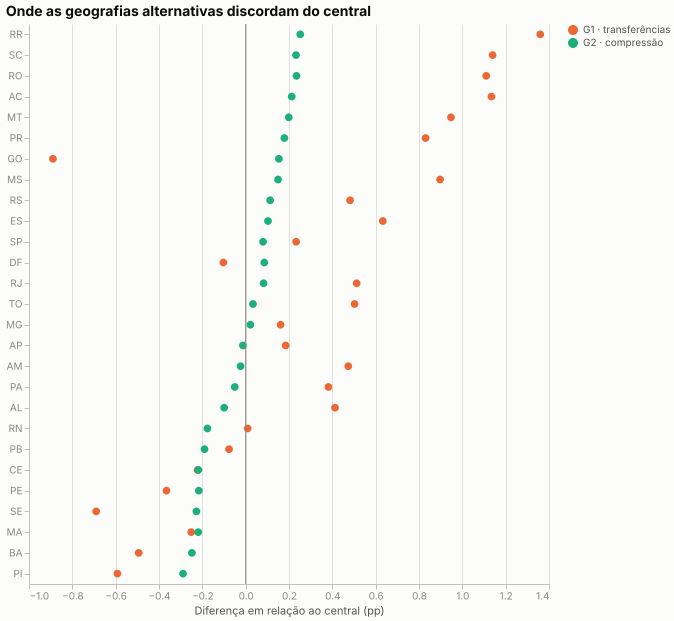

In [7]:
dif = uf.select(
    "uf",
    (pl.col("pt_2p_g1_transferencias") - pl.col("pt_2p")).alias("G1 · transferências"),
    (pl.col("pt_2p_g2_compressao") - pl.col("pt_2p")).alias("G2 · compressão"),
).unpivot(index="uf", variable_name="variante", value_name="diferenca_pp")
resultados.grafico(
    live,
    "B4_geografias",
    (
        alt.Chart(dif)
        .mark_circle(size=60, opacity=1)
        .encode(
            x=alt.X("diferenca_pp:Q", title="Diferença em relação ao central (pp)"),
            y=alt.Y("uf:N", sort=ordem_uf, title=None),
            color=alt.Color("variante:N", scale=alt.Scale(range=SERIES[1:3]), title=None),
            tooltip=[
                alt.Tooltip("uf:N", title="UF"),
                alt.Tooltip("variante:N", title="Variante"),
                alt.Tooltip("diferenca_pp:Q", title="Diferença (pp)", format="+.2f"),
            ],
        )
        + alt.Chart().mark_rule(color=TINTA["apagada"]).encode(x=alt.datum(0))
    ).properties(
        width=520, height=560, title="Onde as geografias alternativas discordam do central"
    ),
)

**O que observar:** as duas alternativas **comprimem** o mapa em relação ao central, cada uma
por um motivo.

- **G1:** os votos transferidos têm a mesma mistura em todo lugar (sobretudo para Flávio), então
  pesam mais contra Lula onde ele é forte (Nordeste) do que onde já é fraco. Calibrado no mesmo
  total nacional, isso devolve votos a Lula no Sul, no Norte e no Centro-Oeste. A exceção é
  **Goiás**, onde Caiado foi forte e a G1 tira de Lula mesmo assim.
- **G2:** puxa os extremos para o centro, com a intensidade estimada em 2022, de forma mais
  suave e sem depender de quem foram os candidatos eliminados.

Depois de 25/10, o resultado diz qual delas descreve melhor o que aconteceu.

## Depois da eleição

Quando o TSE publicar o 2º turno: `uv run dvc update` nos arquivos de 2026, `just repro` e a
avaliação registrada em `docs/hipoteses.md` (B4): erro do nível, RMSE de cada geografia
recalibrada no nível real, comparação com a referência ingênua e erro por UF.

In [8]:
live.end()